# Project 04: Hospital Readmission Prediction

## Notebook 01: EDA and ICD-9 Mapping

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create folders if not exists
os.makedirs('../models', exist_ok=True)
os.makedirs('../charts', exist_ok=True)
os.makedirs('../data/processed', exist_ok=True)

# Load the dataset
# Source: https://www.kaggle.com/datasets/brandao/diabetes
df = pd.read_csv('../data/raw/diabetic_data.csv')
print(f"Initial Dataset Shape: {df.shape}")
df.head()


Initial Dataset Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


### 2. Basic Cleaning and Handling Duplicate Records

In [2]:

# Replace '?' with NaN
df.replace('?', np.nan, inplace=True)

# Missing value check
print("Missing values per column:\n", df.isnull().sum()[df.isnull().sum() > 0])

# Drop columns with too many missing values (>40%)
# weight, payer_code, medical_specialty are typical candidates here
cols_to_drop = ['weight', 'payer_code', 'medical_specialty']
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')

# Handle duplicate patients (Keep only the first encounter for each patient)
# This is a standard clinical modeling practice to ensure i.i.d samples
df = df.sort_values('encounter_id').drop_duplicates('patient_nbr', keep='first')
print(f"Shape after removing duplicates: {df.shape}")


Missing values per column:
 race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
max_glu_serum        96420
A1Cresult            84748
dtype: int64
Shape after removing duplicates: (71518, 47)


### 3. ICD-9 Clinical Categorization

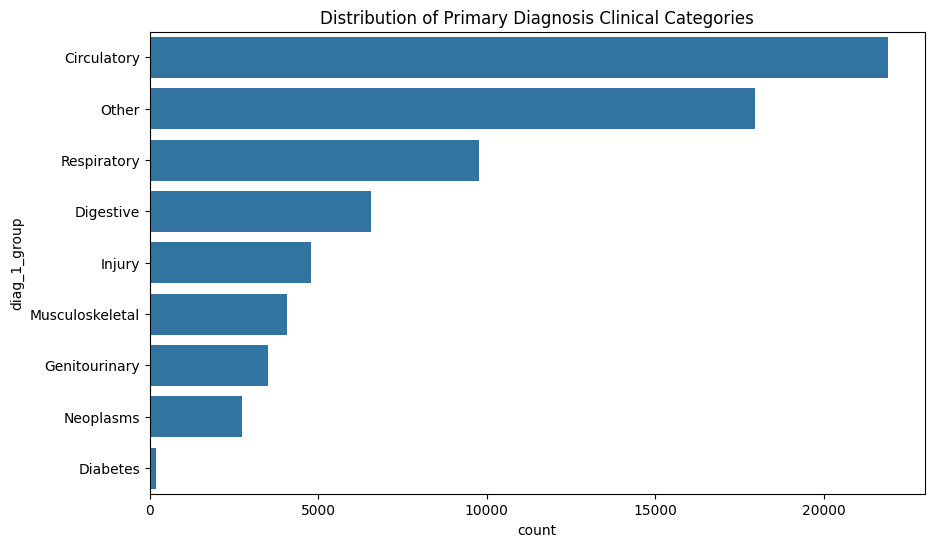

In [3]:

def map_icd9_to_group(code):
    """Grouping ICD-9 codes into 9 high-level clinical categories."""
    if pd.isnull(code):
        return 'Other'
    code_str = str(code)
    if 'V' in code_str or 'E' in code_str:
        return 'Other'
    
    try:
        val = float(code)
        if 390 <= val <= 459 or val == 785:
            return 'Circulatory'
        elif 460 <= val <= 519 or val == 786:
            return 'Respiratory'
        elif 520 <= val <= 579 or val == 787:
            return 'Digestive'
        elif val == 250:
            return 'Diabetes'
        elif 800 <= val <= 999:
            return 'Injury'
        elif 710 <= val <= 739:
            return 'Musculoskeletal'
        elif 580 <= val <= 629 or val == 788:
            return 'Genitourinary'
        elif 140 <= val <= 239:
            return 'Neoplasms'
        else:
            return 'Other'
    except:
        return 'Other'

# Apply grouping to diag_1, diag_2, diag_3
diag_cols = ['diag_1', 'diag_2', 'diag_3']
for col in diag_cols:
    df[f'{col}_group'] = df[col].apply(map_icd9_to_group)

# Visual check of the primary diagnosis distribution
plt.figure(figsize=(10,6))
sns.countplot(y='diag_1_group', data=df, order=df['diag_1_group'].value_counts().index)
plt.title('Distribution of Primary Diagnosis Clinical Categories')
plt.savefig('../charts/diagnosis_distribution.png')
plt.show()


### 4. Binary Target Engineering and Final Save

In [4]:

# Convert target 'readmitted' to binary (30-day readmission)
# '<30' -> 1, others -> 0
df['readmitted_30d'] = (df['readmitted'] == '<30').astype(int)

# Check class balance
print("Class Balance (30-day Readmitted):")
print(df['readmitted_30d'].value_counts(normalize=True))

# Save processed data for the next stage
df.to_csv('../data/processed/readmission_cleaned.csv', index=False)
print("Data saved to ../data/processed/readmission_cleaned.csv")


Class Balance (30-day Readmitted):
readmitted_30d
0    0.912008
1    0.087992
Name: proportion, dtype: float64


Data saved to ../data/processed/readmission_cleaned.csv
